In [227]:
import math
import os
import urllib.request

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams["figure.figsize"] = (6.5, 3.8)
plt.rcParams["axes.grid"] = True
print("torch", torch.__version__)

torch 2.15.0+cpu


In [228]:
URL = "https://raw.githubusercontent.com/karpathy/makemore/master/names.txt"

def load_words(path="names.txt"):
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve(URL, path)
        except Exception as err:
            raise FileNotFoundError(f"names.txt not found and download failed ({err}). Put names.txt next to this notebook.")
    return open(path, "r").read().splitlines()

words = load_words()
print(words[:10])

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']


In [229]:
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [230]:
## Build the dataset

block_size = 3 # context lenght: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:5]:
    print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        x.append(context)
        y.append(ix)
        print(''.join(itos[i] for i in context), '---->', itos[ix])
        context = context[1:] + [ix] # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y) 

emma
... ----> e
..e ----> m
.em ----> m
emm ----> a
mma ----> .
olivia
... ----> o
..o ----> l
.ol ----> i
oli ----> v
liv ----> i
ivi ----> a
via ----> .
ava
... ----> a
..a ----> v
.av ----> a
ava ----> .
isabella
... ----> i
..i ----> s
.is ----> a
isa ----> b
sab ----> e
abe ----> l
bel ----> l
ell ----> a
lla ----> .
sophia
... ----> s
..s ----> o
.so ----> p
sop ----> h
oph ----> i
phi ----> a
hia ----> .


In [231]:
## Build the dataset

block_size = 3 # context lenght: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:5]:
    # print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '---->', itos[ix])
        context = context[1:] + [ix] # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y) 

In [232]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

In [233]:
X

tensor([[ 0,  0,  0],
        [ 0,  0,  5],
        [ 0,  5, 13],
        [ 5, 13, 13],
        [13, 13,  1],
        [ 0,  0,  0],
        [ 0,  0, 15],
        [ 0, 15, 12],
        [15, 12,  9],
        [12,  9, 22],
        [ 9, 22,  9],
        [22,  9,  1],
        [ 0,  0,  0],
        [ 0,  0,  1],
        [ 0,  1, 22],
        [ 1, 22,  1],
        [ 0,  0,  0],
        [ 0,  0,  9],
        [ 0,  9, 19],
        [ 9, 19,  1],
        [19,  1,  2],
        [ 1,  2,  5],
        [ 2,  5, 12],
        [ 5, 12, 12],
        [12, 12,  1],
        [ 0,  0,  0],
        [ 0,  0, 19],
        [ 0, 19, 15],
        [19, 15, 16],
        [15, 16,  8],
        [16,  8,  9],
        [ 8,  9,  1]])

In [234]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [235]:
C = torch.randn((27, 2))

In [236]:
C

tensor([[-0.8505, -0.5091],
        [-0.6844,  0.3044],
        [ 1.6744, -0.3042],
        [ 0.2739, -0.4299],
        [ 0.3628,  0.5729],
        [ 0.1892,  1.0108],
        [ 1.0346, -1.4188],
        [ 0.3214, -0.1646],
        [-0.3003,  0.3207],
        [ 0.6658, -0.6268],
        [ 1.1391,  0.1451],
        [ 0.3827, -0.7143],
        [ 0.7241, -0.9422],
        [ 0.4033,  0.8195],
        [ 0.9635,  0.6935],
        [ 0.7197, -0.1528],
        [-0.9649, -1.4463],
        [ 0.7269, -0.6688],
        [ 0.6975, -0.9066],
        [-0.8447, -0.6158],
        [ 0.1948, -0.0406],
        [-0.7376,  1.5689],
        [-2.1525, -0.2683],
        [ 0.3134,  0.4787],
        [ 1.8857, -1.9144],
        [-0.4347,  0.4516],
        [-0.6355, -0.2500]])

In [237]:
C[5]

tensor([0.1892, 1.0108])

In [238]:
F.one_hot(torch.tensor(5), num_classes=27)

tensor([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0])

In [239]:
F.one_hot(torch.tensor(5), num_classes=27).dtype

torch.int64

In [240]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([0.1892, 1.0108])

In [241]:
C[[5, 6, 6]]

tensor([[ 0.1892,  1.0108],
        [ 1.0346, -1.4188],
        [ 1.0346, -1.4188]])

In [242]:
C[torch.tensor([5, 6, 7])]

tensor([[ 0.1892,  1.0108],
        [ 1.0346, -1.4188],
        [ 0.3214, -0.1646]])

In [243]:
C[X]

tensor([[[-0.8505, -0.5091],
         [-0.8505, -0.5091],
         [-0.8505, -0.5091]],

        [[-0.8505, -0.5091],
         [-0.8505, -0.5091],
         [ 0.1892,  1.0108]],

        [[-0.8505, -0.5091],
         [ 0.1892,  1.0108],
         [ 0.4033,  0.8195]],

        [[ 0.1892,  1.0108],
         [ 0.4033,  0.8195],
         [ 0.4033,  0.8195]],

        [[ 0.4033,  0.8195],
         [ 0.4033,  0.8195],
         [-0.6844,  0.3044]],

        [[-0.8505, -0.5091],
         [-0.8505, -0.5091],
         [-0.8505, -0.5091]],

        [[-0.8505, -0.5091],
         [-0.8505, -0.5091],
         [ 0.7197, -0.1528]],

        [[-0.8505, -0.5091],
         [ 0.7197, -0.1528],
         [ 0.7241, -0.9422]],

        [[ 0.7197, -0.1528],
         [ 0.7241, -0.9422],
         [ 0.6658, -0.6268]],

        [[ 0.7241, -0.9422],
         [ 0.6658, -0.6268],
         [-2.1525, -0.2683]],

        [[ 0.6658, -0.6268],
         [-2.1525, -0.2683],
         [ 0.6658, -0.6268]],

        [[-2.1525, -0

In [244]:
C[X].shape

torch.Size([32, 3, 2])

In [245]:
X[13, 2]

tensor(1)

In [246]:
C[X][13, 2]

tensor([-0.6844,  0.3044])

In [247]:
C[1]

tensor([-0.6844,  0.3044])

In [248]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [249]:
w1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [250]:
emb @ w1 + b

RuntimeError: mm: mat1 and mat2 shapes cannot be multiplied (96x2 and 6x100)

In [251]:
emb[:, 0, :].shape

torch.Size([32, 2])

In [252]:
emb[:, 1, :].shape

torch.Size([32, 2])

In [253]:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape

torch.Size([32, 6])

In [254]:
torch.cat(torch.unbind(emb, 1), 1)

tensor([[-0.8505, -0.5091, -0.8505, -0.5091, -0.8505, -0.5091],
        [-0.8505, -0.5091, -0.8505, -0.5091,  0.1892,  1.0108],
        [-0.8505, -0.5091,  0.1892,  1.0108,  0.4033,  0.8195],
        [ 0.1892,  1.0108,  0.4033,  0.8195,  0.4033,  0.8195],
        [ 0.4033,  0.8195,  0.4033,  0.8195, -0.6844,  0.3044],
        [-0.8505, -0.5091, -0.8505, -0.5091, -0.8505, -0.5091],
        [-0.8505, -0.5091, -0.8505, -0.5091,  0.7197, -0.1528],
        [-0.8505, -0.5091,  0.7197, -0.1528,  0.7241, -0.9422],
        [ 0.7197, -0.1528,  0.7241, -0.9422,  0.6658, -0.6268],
        [ 0.7241, -0.9422,  0.6658, -0.6268, -2.1525, -0.2683],
        [ 0.6658, -0.6268, -2.1525, -0.2683,  0.6658, -0.6268],
        [-2.1525, -0.2683,  0.6658, -0.6268, -0.6844,  0.3044],
        [-0.8505, -0.5091, -0.8505, -0.5091, -0.8505, -0.5091],
        [-0.8505, -0.5091, -0.8505, -0.5091, -0.6844,  0.3044],
        [-0.8505, -0.5091, -0.6844,  0.3044, -2.1525, -0.2683],
        [-0.6844,  0.3044, -2.1525, -0.2

In [255]:
torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([32, 6])

In [256]:
a = torch.arange(18)
a

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [257]:
a.shape

torch.Size([18])

In [258]:
a.view(3, 3, 2)

tensor([[[ 0,  1],
         [ 2,  3],
         [ 4,  5]],

        [[ 6,  7],
         [ 8,  9],
         [10, 11]],

        [[12, 13],
         [14, 15],
         [16, 17]]])

In [259]:
a.storage()

 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
 12
 13
 14
 15
 16
 17
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 18]

In [260]:
emb.shape

torch.Size([32, 3, 2])

In [261]:
emb.view(32, 6)

tensor([[-0.8505, -0.5091, -0.8505, -0.5091, -0.8505, -0.5091],
        [-0.8505, -0.5091, -0.8505, -0.5091,  0.1892,  1.0108],
        [-0.8505, -0.5091,  0.1892,  1.0108,  0.4033,  0.8195],
        [ 0.1892,  1.0108,  0.4033,  0.8195,  0.4033,  0.8195],
        [ 0.4033,  0.8195,  0.4033,  0.8195, -0.6844,  0.3044],
        [-0.8505, -0.5091, -0.8505, -0.5091, -0.8505, -0.5091],
        [-0.8505, -0.5091, -0.8505, -0.5091,  0.7197, -0.1528],
        [-0.8505, -0.5091,  0.7197, -0.1528,  0.7241, -0.9422],
        [ 0.7197, -0.1528,  0.7241, -0.9422,  0.6658, -0.6268],
        [ 0.7241, -0.9422,  0.6658, -0.6268, -2.1525, -0.2683],
        [ 0.6658, -0.6268, -2.1525, -0.2683,  0.6658, -0.6268],
        [-2.1525, -0.2683,  0.6658, -0.6268, -0.6844,  0.3044],
        [-0.8505, -0.5091, -0.8505, -0.5091, -0.8505, -0.5091],
        [-0.8505, -0.5091, -0.8505, -0.5091, -0.6844,  0.3044],
        [-0.8505, -0.5091, -0.6844,  0.3044, -2.1525, -0.2683],
        [-0.6844,  0.3044, -2.1525, -0.2

In [262]:
emb.view(32, 6) == torch.cat(torch.unbind(emb, 1), 1)

tensor([[True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, T

In [263]:
h = emb.view(32, 6) @ w1 + b1

In [264]:
h

tensor([[ 0.3923,  0.4616,  2.8105,  ...,  1.8367,  0.3017, -1.9501],
        [-0.7818,  1.7352,  3.2979,  ..., -0.3027, -2.8404, -2.8647],
        [-1.2240, -3.4752,  2.0871,  ..., -2.4603, -2.2562, -1.3717],
        ...,
        [-0.0521,  6.2872,  3.1352,  ...,  1.2257, -0.3514, -2.0552],
        [-0.8198, -2.4696,  0.9140,  ..., -0.2826,  0.6535, -0.3995],
        [-0.3490,  1.4076,  3.0804,  ..., -0.8690, -0.7435, -1.3454]])

In [265]:
h.shape

torch.Size([32, 100])

In [266]:
h = emb.view(emb.shape[0], 6) @ w1 + b1
h.shape

torch.Size([32, 100])

In [267]:
h = emb.view(-1, 6) @ w1 + b1
h.shape

torch.Size([32, 100])

In [268]:
h = torch.tanh(emb.view(-1, 6) @ w1 + b1)
h

tensor([[ 0.3734,  0.4314,  0.9928,  ...,  0.9505,  0.2929, -0.9603],
        [-0.6538,  0.9397,  0.9973,  ..., -0.2938, -0.9932, -0.9935],
        [-0.8408, -0.9981,  0.9697,  ..., -0.9855, -0.9783, -0.8791],
        ...,
        [-0.0521,  1.0000,  0.9962,  ...,  0.8413, -0.3376, -0.9677],
        [-0.6750, -0.9858,  0.7230,  ..., -0.2753,  0.5740, -0.3795],
        [-0.3354,  0.8870,  0.9958,  ..., -0.7009, -0.6312, -0.8730]])

In [269]:
h.shape

torch.Size([32, 100])

In [270]:
(emb.view(-1, 6) @ w1 + b1).shape

torch.Size([32, 100])

In [271]:
b1.shape

torch.Size([100])

In [272]:
# 32 , 100
#  1,  1000
# it's called brodcasting of vector

In [273]:
w2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [274]:
logits = h @ w2 + b2
logits

tensor([[ -7.4948,  -3.1523,   7.9684, -17.6233, -12.3103,   7.5389,  -5.1331,
           2.8287, -10.6369,   0.3461,   0.9583,  12.0955,   3.0876,   0.4567,
           0.3172, -13.5142, -13.8994,   3.2240,  -8.6305,   4.3418,  -2.1015,
           9.3112,  -3.6995,  16.3346,   6.3888, -10.3252,   0.0340],
        [  0.5097,  11.6381,  -8.6548,  -9.4815,  -6.1723,   3.3714,  -3.2163,
          -7.7332, -12.7729,  -5.8696,   2.1733,  18.6216,   6.4947,   9.5159,
           5.5538,  -3.4069,  -7.9495,  -2.6822,   6.9078, -10.3887,   7.4200,
           2.6780,   3.4182,  -2.3676,  14.7808, -12.6383,   7.4484],
        [ -1.5014,   7.6027, -12.7248,   1.9976,  -3.2440,  -2.3497,  -2.8034,
          -7.1748, -10.4985,  -3.3676,   8.6230,   9.1879,   0.4118,  -0.9390,
           9.2947,   1.4896,  -2.5200,  -6.0987,   0.2201, -11.0722,   9.6240,
          -7.1195,   5.9885,  -9.7557,  -1.3125, -11.9973,   2.8699],
        [  3.2581,   9.8278, -13.0441,   8.0824,   5.9070,  -3.5129,  -7.2205,


In [275]:
logits.shape

torch.Size([32, 27])

In [276]:
counts = logits.exp()
counts

tensor([[5.5598e-04, 4.2755e-02, 2.8883e+03, 2.2196e-08, 4.5050e-06, 1.8797e+03,
         5.8984e-03, 1.6924e+01, 2.4012e-05, 1.4135e+00, 2.6072e+00, 1.7906e+05,
         2.1925e+01, 1.5788e+00, 1.3733e+00, 1.3517e-06, 9.1950e-07, 2.5128e+01,
         1.7857e-04, 7.6844e+01, 1.2227e-01, 1.1061e+04, 2.4736e-02, 1.2417e+07,
         5.9514e+02, 3.2797e-05, 1.0346e+00],
        [1.6647e+00, 1.1333e+05, 1.7428e-04, 7.6252e-05, 2.0864e-03, 2.9120e+01,
         4.0102e-02, 4.3806e-04, 2.8366e-06, 2.8241e-03, 8.7876e+00, 1.2226e+08,
         6.6162e+02, 1.3574e+04, 2.5823e+02, 3.3144e-02, 3.5282e-04, 6.8415e-02,
         1.0001e+03, 3.0779e-05, 1.6691e+03, 1.4557e+01, 3.0515e+01, 9.3707e-02,
         2.6255e+06, 3.2452e-06, 1.7170e+03],
        [2.2281e-01, 2.0036e+03, 2.9763e-06, 7.3717e+00, 3.9009e-02, 9.5399e-02,
         6.0604e-02, 7.6561e-04, 2.7578e-05, 3.4472e-02, 5.5581e+03, 9.7784e+03,
         1.5095e+00, 3.9101e-01, 1.0880e+04, 4.4353e+00, 8.0462e-02, 2.2458e-03,
         1.2462e+

In [277]:
prob = counts / counts.sum(1, keepdims=True)
prob[0]

tensor([4.4080e-11, 3.3897e-09, 2.2899e-04, 1.7598e-15, 3.5718e-13, 1.4903e-04,
        4.6764e-10, 1.3418e-06, 1.9038e-12, 1.1207e-07, 2.0670e-07, 1.4196e-02,
        1.7383e-06, 1.2517e-07, 1.0888e-07, 1.0717e-13, 7.2901e-14, 1.9923e-06,
        1.4158e-11, 6.0925e-06, 9.6942e-09, 8.7696e-04, 1.9611e-09, 9.8449e-01,
        4.7184e-05, 2.6002e-12, 8.2028e-08])

In [278]:
prob[0].sum()

tensor(1.)

In [279]:
prob.shape

torch.Size([32, 27])

In [280]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [281]:
torch.arange(32)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [282]:
prob[torch.arange(32), Y]

tensor([1.4903e-04, 1.0858e-04, 8.9322e-06, 8.4240e-05, 1.5464e-03, 1.0717e-13,
        2.6440e-07, 1.9402e-01, 7.7023e-08, 2.7825e-04, 1.6721e-07, 1.7240e-14,
        3.3897e-09, 2.7615e-07, 2.5278e-12, 3.4474e-05, 1.1207e-07, 8.8309e-14,
        2.1832e-08, 2.6359e-09, 5.5343e-09, 8.2922e-11, 1.1840e-09, 5.6092e-03,
        1.1579e-05, 6.0925e-06, 4.1010e-14, 3.3580e-10, 1.3119e-08, 1.2639e-11,
        1.0882e-05, 3.9859e-09])

In [283]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(16.7800)

In [284]:
# forward pass
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
w1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
w2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]

In [285]:
sum(p.nelement() for p in parameters)

3481

In [286]:
emb = C[X] #  (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ w1 + b1) # (32, 100)
logits = h @ w2 + b2 # (32, 27)
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(17.7697)

In [287]:
loss = F.cross_entropy(logits, Y)
loss

tensor(17.7697)

In [288]:
logits = torch.tensor([-2, -3, 0, 5])
counts = logits.exp()
probs = counts / counts.sum()
probs

tensor([9.0466e-04, 3.3281e-04, 6.6846e-03, 9.9208e-01])

In [289]:
logits = torch.tensor([-100, -3, 0, 5])
counts = logits.exp()
probs = counts / counts.sum()
probs

tensor([0.0000e+00, 3.3311e-04, 6.6906e-03, 9.9298e-01])

In [290]:
logits = torch.tensor([-100, -3, 0, 100])
counts = logits.exp()
probs = counts / counts.sum()
probs

tensor([0., 0., 0., nan])

In [291]:
counts

tensor([3.7835e-44, 4.9787e-02, 1.0000e+00,        inf])

In [292]:
logits = torch.tensor([-2, -3, 0, 5]) - 5
counts = logits.exp()
probs = counts / counts.sum()
probs

tensor([9.0466e-04, 3.3281e-04, 6.6846e-03, 9.9208e-01])

In [293]:
logits = torch.tensor([-2, -3, 0, 100]) - 90
counts = logits.exp()
probs = counts / counts.sum()
probs

tensor([5.6052e-45, 1.4013e-45, 3.7835e-44, 1.0000e+00])

In [294]:
for p in parameters:
    p.requires_grad = True

In [ ]:
for _ in range(10):


    
    # forwoard pass
    emb = C[X] #  (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ w1 + b1) # (32, 100)
    logits = h @ w2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Y)


    # Backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += 0.1 * p.grad

print(loss.item())

87.97529602050781


In [296]:
logits.max(1)

torch.return_types.max(
values=tensor([102.2491, 104.0574,  88.8698,  77.9275, 105.3187, 102.2491,  97.7390,
         57.0598,  25.9259,  23.0222,  89.9557,  90.2002, 102.2491, 105.1200,
        100.1575,  82.7111, 102.2491, 103.4490, 104.5837,  99.6475,  97.2494,
         88.3335,  43.6625,  24.3372,  19.0471, 102.2491, 104.6872,  94.3562,
         57.0331,  22.2165,  66.3306,  99.7606], grad_fn=<MaxBackward0>),
indices=tensor([10, 10, 10, 10, 10, 10, 10, 10,  9, 21, 10, 10, 10, 10, 10, 10, 10, 10,
        10, 10, 10, 10, 10, 23, 20, 10, 10, 10, 10,  9, 10, 10]))

In [297]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [301]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [302]:
for _ in range(10):

    # minibatch construct
    ix = torch.randint(0, X.shape[0], (32,))
    
    # forwoard pass
    emb = C[X[ix]] #  (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ w1 + b1) # (32, 100)
    logits = h @ w2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])


    # Backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += 0.1 * p.grad

print(loss.item())

203.57583618164062


In [303]:
lri = []
lossi = []
for i in range(1000):

    # minibatch construct
    ix = torch.randint(0, X.shape[0], (32,))
    
    # forwoard pass
    emb = C[X[ix]] #  (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ w1 + b1) # (32, 100)
    logits = h @ w2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])


    # Backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    lr = lrs[i]
    for p in parameters:
        p.data += 0.1 * p.grad

    # trackstats
    lri.append(lr)
    lossi.append(loss.item())

print(loss.item())

11468.7294921875


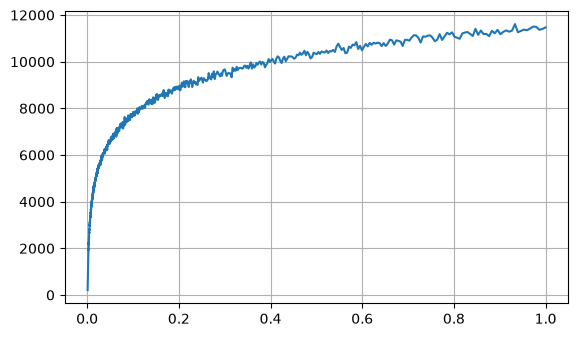

In [304]:
plt.plot(lri, lossi)

In [305]:
# training split, dev/validation split , test split
# 80%, 10%, 10%
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [ ]:
we can increase the neural net in w1 and 22

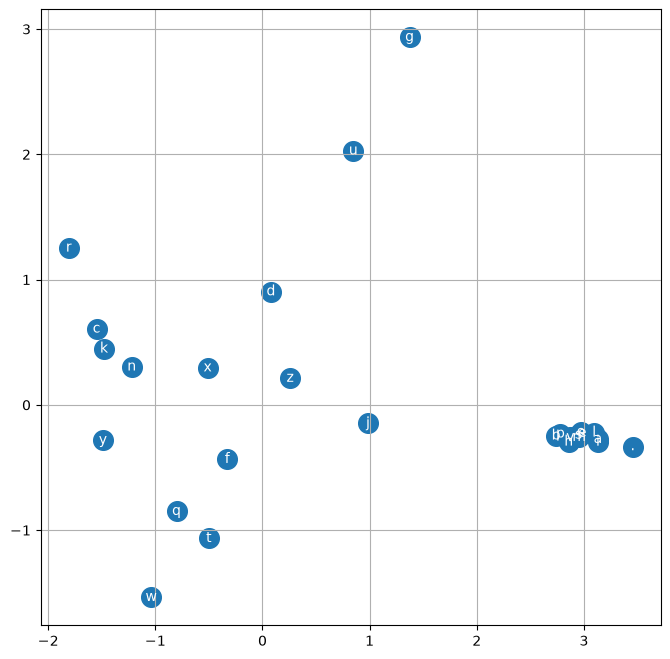

In [306]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')